Imports and paths

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, make_scorer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
raw_data_dir = ROOT / "data" / "raw"
processed_data_dir = ROOT / "data" / "processed"
reports_figures = ROOT / "reports" / "figures"

In [3]:
# The models predict the log of the market value: go back to euros before computing the error, in M€.
def mae_m_eur(y_true, y_pred):
    return mean_absolute_error(np.exp(y_true), np.exp(y_pred)) / 1e6

Loading the data

In [4]:
pl_players_2025_26 = pd.read_csv(processed_data_dir / "pl_players_2025_26.csv")
pl_players_2025_26.tail()

,player_id,name,club_id,club,position,sub_position,international_caps,age,contract_years_left,appearances,minutes_played,goals,assists,value_start_eur,value_end_eur,value_change_eur,value_change_pct
511,1111589,El Hadji Malick Diouf,379,West Ham United,Defender,Left-Back,23,21.4,4.1,32,2711,0,5,18000000.0,28000000.0,10000000.0,55.6
512,1124005,Christantus Uche,873,Crystal Palace,Attack,Centre-Forward,3,23.0,2.1,14,159,0,1,15000000.0,12000000.0,-3000000.0,-20.0
513,1193867,Pedro Lima,543,Wolverhampton Wanderers,Defender,Right-Back,1,19.9,3.1,9,259,0,0,5000000.0,4000000.0,-1000000.0,-20.0
514,1230661,Mateus Mané,543,Wolverhampton Wanderers,Midfield,Attacking Midfield,2,18.7,3.1,27,1790,3,2,200000.0,20000000.0,19800000.0,9900.0
515,1322090,Jocelin Ta Bi,289,Sunderland AFC,Attack,Right Winger,3,21.3,4.1,1,39,0,0,125000.0,2500000.0,2375000.0,1900.0


## Data preparation

The features chosen to predict the market value.

In [5]:
features = ["club", "sub_position", "international_caps", "age", "contract_years_left", "minutes_played", "goals", "assists"]
model_data = pl_players_2025_26[features].copy()

The target is the log(value_end_eur).

In [6]:
model_data["value_end_log"] = np.log(pl_players_2025_26["value_end_eur"])

We need to replace categorical features with numerical ones. We will use one-hot encoding for this.

In [7]:
str_columns = model_data.select_dtypes(include=['object', 'string']).columns.tolist()
for column in str_columns : 
    print(f"Number of {column} : {model_data[column].nunique()}")

Number of club : 20
Number of sub_position : 11


We will now have 20 club_columns, 11 sub_positions columns, encoded as 0 or 1, one per club and one per sub_position.

In [8]:
model_data = pd.get_dummies(model_data, columns=["sub_position", "club"], dtype=int)

In [9]:
model_data.columns

Index(['international_caps', 'age', 'contract_years_left', 'minutes_played',
       'goals', 'assists', 'value_end_log', 'sub_position_Attacking Midfield',
       'sub_position_Central Midfield', 'sub_position_Centre-Back',
       'sub_position_Centre-Forward', 'sub_position_Defensive Midfield',
       'sub_position_Goalkeeper', 'sub_position_Left Midfield',
       'sub_position_Left Winger', 'sub_position_Left-Back',
       'sub_position_Right Winger', 'sub_position_Right-Back',
       'club_AFC Bournemouth', 'club_Arsenal FC', 'club_Aston Villa',
       'club_Brentford FC', 'club_Brighton & Hove Albion', 'club_Burnley FC',
       'club_Chelsea FC', 'club_Crystal Palace', 'club_Everton FC',
       'club_Fulham FC', 'club_Leeds United', 'club_Liverpool FC',
       'club_Manchester City', 'club_Manchester United',
       'club_Newcastle United', 'club_Nottingham Forest',
       'club_Sunderland AFC', 'club_Tottenham Hotspur', 'club_West Ham United',
       'club_Wolverhampton Wanderers'

In [10]:
model_data.shape

(516, 38)

## Features and target

In [11]:
y = model_data["value_end_log"]
X = model_data.drop(columns="value_end_log")

## Train / test split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=10)

## Linear regression model

In [13]:
linear_model = LinearRegression().fit(X_train, y_train)

## Model evaluation

### On the test set

In [14]:
y_predicted = linear_model.predict(X_test)

In [15]:
mae = mae_m_eur(y_test, y_predicted)
print(f"Mean Absolute Error (MAE) : {mae:.1f} M€")

Mean Absolute Error (MAE) : 9.5 M€


In [16]:
r2 = r2_score(y_test, y_predicted)
print(f"R² score on the test dataset : {r2:.2f}")

R² score on the test dataset : 0.61


The model explains 61% of the variations in player market value, and on average, its estimate varies by 9.5M€ from the actual value.

### On the training set

We can test the model behavior by looking at its predictions on the training set it was trained on.

In [17]:
y_predicted_train = linear_model.predict(X_train)
r2 = r2_score(y_train, y_predicted_train)
print(f"R² score on the training dataset : {r2:.2f}")

R² score on the training dataset : 0.69


The score is slightly better on the training set (0.69) than on the test set (0.61), which is expected.

### Dummy model

In [18]:
dummy_model = DummyRegressor().fit(X_train, y_train)

y_predicted_dummy = dummy_model.predict(X_test)

mae = mae_m_eur(y_test, y_predicted_dummy)
print("------- Dummy Model -------")
print(f"Mean Absolute Error (MAE)  : {mae:.1f} M€")
r2 = r2_score(y_test, y_predicted_dummy)
print(f"R² score : {r2:.2f}")

------- Dummy Model -------
Mean Absolute Error (MAE)  : 18.0 M€
R² score : -0.02


The dummy model, which predicts the same value for every player (14 M€), is on average 18.0 M€ away from the real market value, and its R² is close to 0: predicting the mean explains nothing. 

The linear regression, 9.5 M€ away on average, makes half as many mistakes: it is clearly learning something.

## Random forest model

In [19]:
rf_model = RandomForestRegressor(random_state=10)
rf_model.fit(X_train, y_train)

y_predicted_rf = rf_model.predict(X_test)

mae = mae_m_eur(y_test, y_predicted_rf)
r2 = r2_score(y_test, y_predicted_rf)

print("------- Random Forest Regressor -------")
print(f"Mean Absolute Error : {mae:.1f} M€")
print(f"R² score : {r2:.2f}")

------- Random Forest Regressor -------
Mean Absolute Error : 8.7 M€
R² score : 0.75


The random forest model is explaining 75% of the market value variations on the test set with an average error of 8.7 M€.

### On the training set

In [20]:
y_predicted_train_rf = rf_model.predict(X_train)
r2 = r2_score(y_train, y_predicted_train_rf)
mae = mae_m_eur(y_train, y_predicted_train_rf)
print("------- Random Forest Regressor (on the training set) -------")
print(f"Mean Absolute Error : {mae:.1f} M€")
print(f"R² score : {r2:.2f}")

------- Random Forest Regressor (on the training set) -------
Mean Absolute Error : 3.2 M€
R² score : 0.97


We can clearly see that the random forest model is overfitting the training set : it explains almost all the variations in the market value (R² ≈ 0.97) and its average error is very low (3.2 M€).

## Cross-validation

In [21]:
kfold = KFold(n_splits=5, shuffle=True, random_state=10)
mae_scorer = make_scorer(mae_m_eur, greater_is_better=False)

r2_scores_lr = cross_val_score(LinearRegression(), X, y, cv=kfold, scoring="r2")
r2_scores_rf = cross_val_score(RandomForestRegressor(random_state=10), X, y, cv=kfold, scoring="r2")

mae_scores_lr = -cross_val_score(LinearRegression(), X, y, cv=kfold, scoring=mae_scorer)
mae_scores_rf = -cross_val_score(RandomForestRegressor(random_state=10), X, y, cv=kfold, scoring=mae_scorer)

print("======= Linear Regression =======")
print("--- R² Score ---")
print(f"Mean : {r2_scores_lr.mean()*100:.1f}%")
print(f"SD : {r2_scores_lr.std()*100:.1f}%")
print("--- MAE Score ---")
print(f"Mean : {mae_scores_lr.mean():.1f} M€")
print(f"SD : {mae_scores_lr.std():.1f} M€")

print("\n======= Random Forest Regressor =======")
print("--- R² Score ---")
print(f"Mean : {r2_scores_rf.mean()*100:.1f}%")
print(f"SD : {r2_scores_rf.std()*100:.1f}%")
print("--- MAE Score ---")
print(f"Mean : {mae_scores_rf.mean():.1f} M€")
print(f"SD : {mae_scores_rf.std():.1f} M€")

======= Linear Regression =======
--- R² Score ---
Mean : 61.6%
SD : 3.6%
--- MAE Score ---
Mean : 10.1 M€
SD : 2.0 M€

======= Random Forest Regressor =======
--- R² Score ---
Mean : 77.1%
SD : 3.0%
--- MAE Score ---
Mean : 7.8 M€
SD : 0.8 M€


With 5-fold cross-validation, the random forest performs better than linear regression in each split : on average, it explains 77% of the variations in market value (compared to 62%), with an average error of 7.8 million euros (compared to 10.1 million euros). It is also more stable across cross-validations (standard deviation of 0.8 million euros against 2.0 million euros), which indicates better results are not due to random sampling.

## Comparison table

| Model | MAE (M€) | R² |
|---|---:|---:|
| Dummy model | 18.0 | -0.02 |
| Linear Regression (baseline) | 9.5 | 0.61 |
| Random Forest | **8.7** | **0.75** |

## Features importance

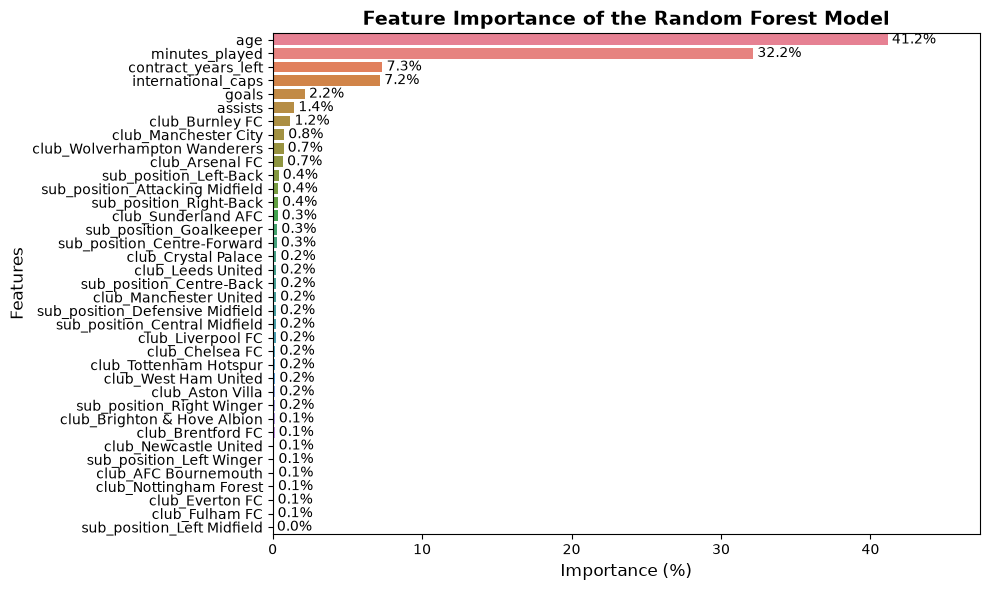

In [22]:
feat_importances = pd.DataFrame(
    {
        "Feature": X.columns,
        "Importance": rf_model.feature_importances_,
    }
)

feat_importances["Importance (%)"] = feat_importances["Importance"] * 100

feat_importances = feat_importances.sort_values(
    by="Importance (%)",
    ascending=False,
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x="Importance (%)",
    y="Feature",
    data=feat_importances,
    hue="Feature",
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
    )

plt.title(
    "Feature Importance of the Random Forest Model",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Importance (%)", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.xlim(0, feat_importances["Importance (%)"].max() * 1.15)
plt.tight_layout()
plt.show()


The age and the minutes played are by far the most used variables by the random forest. The club and the position look unimportant here.

We can group by club and sub_position features to facilitate the interpretation of the model.

In [23]:
importances = pd.Series(rf_model.feature_importances_, index=rf_model.feature_names_in_)

def original_feature(column):
    for prefix in ["club_", "sub_position_"]:
        if column.startswith(prefix):
            return prefix[:-1]   
    return column

grouped_importances = (
    importances.groupby(importances.index.map(original_feature)).sum().sort_values(ascending=False)
)

grouped_importances

age                    0.411581
minutes_played         0.321527
contract_years_left    0.073455
international_caps     0.071872
club                   0.059427
sub_position           0.026208
goals                  0.021516
assists                0.014413
dtype: float64

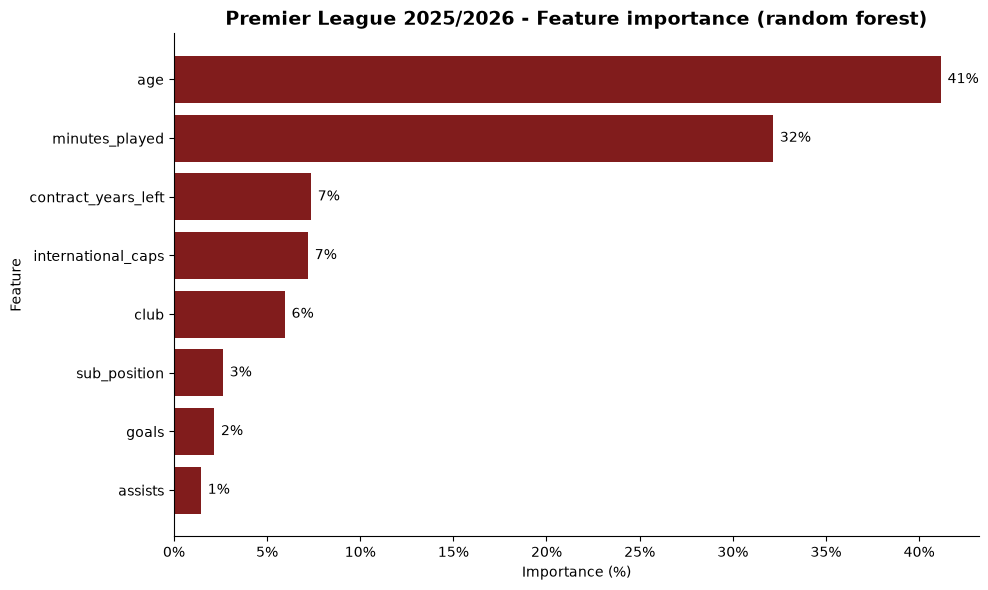

In [24]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(grouped_importances.index, grouped_importances, color="#811C1C")
ax.bar_label(ax.containers[0], labels=[f"{v:.0%}" for v in grouped_importances], padding=5)
ax.invert_yaxis()

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlabel("Importance (%)")
ax.set_ylabel("Feature")
ax.set_title("Premier League 2025/2026 - Feature importance (random forest)", fontsize=14, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(reports_figures / "feature_importance.png", dpi=150)
plt.show()

The age (41%) and the minutes played (32%) drive most of the random forest’s decisions, followed by the contract length, the international caps and the club (6 to 7% each). The goals and assists matter little once the playing time is known. 

The importances do not tell whether a variable makes the value go up or down, only how much the model relies on it.

## Error analysis

Let's look at the errors made by the random forest model on the market value of players in the test set.

We can suppose that the model is more likely to make mistakes on players with very high market values because they are rare and the model doesn't have a big enough sample to learn from.

In [25]:
# One row per test player: real value, value estimated by the random forest, and the error, in M€.
errors = pl_players_2025_26.loc[X_test.index, ["name", "club", "position", "age"]].copy()
errors["real_value_m_eur"] = np.exp(y_test) / 1e6
errors["estimated_value_m_eur"] = np.exp(y_predicted_rf) / 1e6

# Error > 0: the model overestimates the player, error < 0: it underestimates him.
errors["error_m_eur"] = errors["estimated_value_m_eur"] - errors["real_value_m_eur"]
errors["abs_error_m_eur"] = errors["error_m_eur"].abs()
errors["abs_error_pct"] = 100 * errors["abs_error_m_eur"] / errors["real_value_m_eur"]

errors.sort_values("abs_error_m_eur", ascending=False).head(10).round(1)

,name,club,position,age,real_value_m_eur,estimated_value_m_eur,error_m_eur,abs_error_m_eur,abs_error_pct
288,William Saliba,Arsenal FC,Defender,25.2,100.0,43.1,-56.9,56.9,56.9
350,Florian Wirtz,Liverpool FC,Midfield,23.1,100.0,49.0,-51.0,51.0,51.0
501,Estêvão,Chelsea FC,Attack,19.1,80.0,31.2,-48.8,48.8,61.0
241,Gabriel,Arsenal FC,Defender,28.5,75.0,30.2,-44.8,44.8,59.7
329,Elliot Anderson,Nottingham Forest,Midfield,23.6,75.0,41.3,-33.7,33.7,44.9
332,Cole Palmer,Chelsea FC,Midfield,24.1,100.0,66.4,-33.6,33.6,33.6
88,Rúben Dias,Manchester City,Defender,29.1,55.0,25.8,-29.2,29.2,53.1
119,Martin Ødegaard,Arsenal FC,Midfield,27.5,65.0,36.8,-28.2,28.2,43.3
299,Tino Livramento,Newcastle United,Defender,23.6,45.0,17.3,-27.7,27.7,61.6
249,Dominik Szoboszlai,Liverpool FC,Midfield,25.6,100.0,73.6,-26.4,26.4,26.4


As expected, the mistakes are bigger for the players with a market value of 50 M€ or more.

In [26]:
errors[errors["real_value_m_eur"] >= 50].sort_values("error_m_eur").round(1)

,name,club,position,age,real_value_m_eur,estimated_value_m_eur,error_m_eur,abs_error_m_eur,abs_error_pct
288,William Saliba,Arsenal FC,Defender,25.2,100.0,43.1,-56.9,56.9,56.9
350,Florian Wirtz,Liverpool FC,Midfield,23.1,100.0,49.0,-51.0,51.0,51.0
501,Estêvão,Chelsea FC,Attack,19.1,80.0,31.2,-48.8,48.8,61.0
241,Gabriel,Arsenal FC,Defender,28.5,75.0,30.2,-44.8,44.8,59.7
329,Elliot Anderson,Nottingham Forest,Midfield,23.6,75.0,41.3,-33.7,33.7,44.9
332,Cole Palmer,Chelsea FC,Midfield,24.1,100.0,66.4,-33.6,33.6,33.6
88,Rúben Dias,Manchester City,Defender,29.1,55.0,25.8,-29.2,29.2,53.1
119,Martin Ødegaard,Arsenal FC,Midfield,27.5,65.0,36.8,-28.2,28.2,43.3
249,Dominik Szoboszlai,Liverpool FC,Midfield,25.6,100.0,73.6,-26.4,26.4,26.4
212,Bryan Mbeumo,Manchester United,Attack,26.8,75.0,64.0,-11.0,11.0,14.7


#### Comparison between groups

In [27]:
value_groups = pd.cut(
    errors["real_value_m_eur"], bins=[0, 10, 20, 50, float("inf")], labels=["< 10", "10-20", "20-50", "50+"], right=False
)

# mean_error_m_eur keeps the sign : underestimated or overestimated
# mean_abs_error_m_eur and mean_abs_error_pct measure the size of the error, in M€ and in % of the real value.
error_summary = errors.groupby(value_groups, observed=True).agg(
    players=("name", "count"),
    mean_error_m_eur=("error_m_eur", "mean"),
    mean_abs_error_m_eur=("abs_error_m_eur", "mean"),
    mean_abs_error_pct=("abs_error_pct", "mean"),
).rename_axis("real_value_m_eur")


error_summary.round(1)

,players,mean_error_m_eur,mean_abs_error_m_eur,mean_abs_error_pct
real_value_m_eur,,,,
< 10,24,2.5,3.1,109.7
10-20,27,1.7,5.4,37.4
20-50,39,-1.0,7.7,25.4
50+,14,-26.9,27.0,33.2


The model is particularly reliable for players whose values are between 20 and 50 M€. It tends to bring values towards the middle : cheaper players are slightly overestimated, while stars worth 50M€ or more are almost always underestimated (−27M€ on average), because they are rare (14 players in the test set) and a random forest cannot predict beyond the values it has observed. The errors are proportionally largest for players valued at less than 10 M€ (110%).

In [28]:
position_summary = errors.groupby("position", observed=True).agg(
    players=("name", "count"),
    mean_error_m_eur=("error_m_eur", "mean"),
    mean_abs_error_m_eur=("abs_error_m_eur", "mean"),
    mean_abs_error_pct=("abs_error_pct", "mean"),
)

position_summary.round(1)

,players,mean_error_m_eur,mean_abs_error_m_eur,mean_abs_error_pct
position,,,,
Attack,34,-1.5,7.8,52.1
Defender,39,-2.0,7.9,45.4
Goalkeeper,5,-3.3,4.0,51.2
Midfield,26,-6.2,11.8,50.1


The error doesn't depend on the position, with about 50% of the real value for every position. The midfielders seem to be a bit more underestimated, maybe because of the presence of a few very expensive players in this group. With only 5 goalkeepers, it's not reliable.

Let's look at the midfielders :

In [29]:
errors[errors["position"] == "Midfield"].sort_values("real_value_m_eur", ascending=False).head(10).round(1)

,name,club,position,age,real_value_m_eur,estimated_value_m_eur,error_m_eur,abs_error_m_eur,abs_error_pct
249,Dominik Szoboszlai,Liverpool FC,Midfield,25.6,100.0,73.6,-26.4,26.4,26.4
350,Florian Wirtz,Liverpool FC,Midfield,23.1,100.0,49.0,-51.0,51.0,51.0
332,Cole Palmer,Chelsea FC,Midfield,24.1,100.0,66.4,-33.6,33.6,33.6
329,Elliot Anderson,Nottingham Forest,Midfield,23.6,75.0,41.3,-33.7,33.7,44.9
119,Martin Ødegaard,Arsenal FC,Midfield,27.5,65.0,36.8,-28.2,28.2,43.3
278,Amadou Onana,Aston Villa,Midfield,24.8,45.0,33.7,-11.3,11.3,25.0
418,Noah Sadiki,Sunderland AFC,Midfield,21.5,35.0,33.6,-1.4,1.4,3.9
266,Kiernan Dewsbury-Hall,Everton FC,Midfield,27.7,35.0,45.7,10.7,10.7,30.6
238,Curtis Jones,Liverpool FC,Midfield,25.3,35.0,27.6,-7.4,7.4,21.2
464,Archie Gray,Tottenham Hotspur,Midfield,20.2,35.0,32.7,-2.3,2.3,6.7


The 5 most expensive midfielders are strongly underestimated, and they pull the mean error of the whole group down: it is the star effect again, not a position effect.

## Conclusion

- **Performance** : the random forest explains 75% of the differences in market value between players on the test set, against 61% for the linear regression. On average, its estimate is 8.7 M€ away from the real market value, against 9.5 M€ for the linear regression. The 5 fold cross-validation confirms it (77% against 62%), so this result does not come from a lucky split.
- **Most influential variables** : the age (41%) and the minutes played (32%) drive most of the model’s decisions, followed by the contract length, the international caps and the club (6 to 7% each). The goals, assists and position matter little once the previous features are known. The importance shows how much the model relies on a variable, not whether it makes the value go up or down.
- **Errors** : the model pulls the values towards the middle. The stars worth 50 M€ or more are almost always underestimated (−27 M€ on average), because they are rare and a random forest cannot predict beyond the values it has seen. In proportion, the cheap players are the least well estimated. The errors do not depend on the position.
- **Limits** : The model is trained on one season, on a single competition, a small set of players. It explains 75% of the differences in market value (R² score) : the other 25% come from things that are not in the data, like the talent, the hype or the injuries.